# 10 · Heat doublet in MODFLOW 6 (GWE), checked against SubsurfiX

The doublet of the README animation (30 °C water injected into an 80 °C reservoir for 30 years, on a small
layered block model) run in
SubsurfiX (`run_heat`) and again in MODFLOW 6 with its groundwater-energy model, GWE
([Langevin et al. 2024](https://doi.org/10.5066/P9FL1JCC)), through FloPy
([Bakker et al. 2016](https://doi.org/10.1111/gwat.12413)). `subsurfix.modflow_heat` (experimental) converts the
grid, permeability, wells and thermal properties. Both wells are open in every layer: MODFLOW 6 first solves the
flow with multi-aquifer wells (MAW) using the same Peaceman indices as SubsurfiX, and its per-layer well rates then
drive the GWE heat run. Needs the `mf6` program
(6.5 or newer): `get-modflow :`. Thermal properties are illustrative (notebook 06 values).

## Setup

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")
from IPython.display import Markdown, display
from block_model import column_wells, describe, layered_block

## The block model
A self-contained layered block (`block_model.py` next to this notebook, no external data): 10 × 10 × 12 cells of
500 × 500 × 5 m in four units of three layers, kv/kh = 0.1. Injector INJ at column (5, 5) (0.1 m³/s) and producer
PROD at (2, 2) (20 MPa), both open in all layers, so MODFLOW 6 needs its multi-layer well path.

In [2]:
from subsurfix import _native as nat
from subsurfix.modflow_heat import HeatDoublet, run_gwf_gwe, find_mf6
assert find_mf6(), "install mf6 with: get-modflow :flopy"
bm = layered_block()
origin, cell, dims, phi, perm, kmd = bm["origin"], bm["cell"], bm["dims"], bm["phi"], bm["perm"], bm["k_md"]
nx, ny, nz = dims
N = nx * ny * nz
INJ, PROD = (5, 5), (2, 2)
wells = column_wells(bm, INJ, PROD, rate=0.1, bhp=2e7)
yr = 3.156e7
years = np.arange(1, 31)
times = [float(y * yr) for y in years]
mu = 5e-4
case = HeatDoublet(origin, cell, dims, perm, phi, np.full(N, 80.0), wells, [30.0, 0.0], times, viscosity=mu, dt_max=0.05 * yr)
display(Markdown(describe(bm)))
print(N, "cells | median k", round(float(np.median(kmd)), 1), "mD")

| Unit | Layers | Porosity | k (mD) |
|---|---|---|---|
| upper sand | 0–2 | 0.12 | 5 |
| main sand | 3–5 | 0.22 | 80 |
| shaly baffle | 6–8 | 0.06 | 0.5 |
| lower sand | 9–11 | 0.16 | 20 |

1200 cells | median k 12.5 mD


## Run both
MODFLOW 6 runs steady flow and transient GWE; SubsurfiX runs `run_heat` on the same case.

In [3]:
import time
t = time.time(); mf = run_gwf_gwe(case, OUT / "mf6_heat"); t_mf = time.time() - t
dbl = nat.FlowModel.from_regular(list(origin), list(cell), list(dims), perm, phi)
t = time.time()
sx = dbl.run_heat(np.full(N, 1 / mu), wells, [30.0, 0.0], np.full(N, 80.0), times, props=case.props, dt_max=0.05 * yr)
t_sx = time.time() - t
T_sx, T_mf = np.asarray(sx["temperature"]), mf["temperature"]
assert np.allclose(mf["times"], times)
pc = wells[1]["cells"]
tp_sx, tp_mf = T_sx[:, pc].mean(axis=1), T_mf[:, pc].mean(axis=1)
print(f"run time: MODFLOW 6 {t_mf:.1f} s, SubsurfiX {t_sx:.1f} s")
print(f"max |dT| anywhere, any year: {np.abs(T_sx - T_mf).max():.2e} degC")
print(f"mean |dT| over cells and years: {np.abs(T_sx - T_mf).mean():.2e} degC")
print(f"max |dT| producer (layer mean): {np.abs(tp_sx - tp_mf).max():.2e} degC")
pd.DataFrame({"year": years, "SubsurfiX": tp_sx, "MODFLOW 6": tp_mf}).set_index("year").iloc[[0, 4, 9, 14, 19, 24, 29]].round(3)

run time: MODFLOW 6 1.5 s, SubsurfiX 0.1 s
max |dT| anywhere, any year: 3.54e-06 degC
mean |dT| over cells and years: 9.12e-07 degC
max |dT| producer (layer mean): 3.12e-06 degC


,SubsurfiX,MODFLOW 6
year,,
1,80.000,80.000
5,79.997,79.997
10,79.943,79.943
15,79.760,79.760
20,79.387,79.387
25,78.792,78.792
30,77.964,77.964


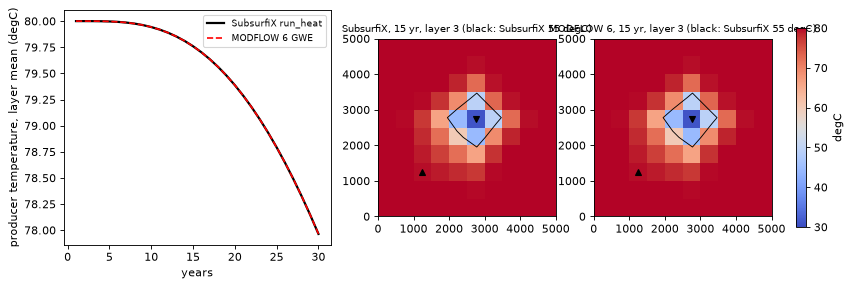

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})
axs[0].plot(years, tp_sx, "k-", lw=2, label="SubsurfiX run_heat"); axs[0].plot(years, tp_mf, "r--", label="MODFLOW 6 GWE")
axs[0].set_xlabel("years"); axs[0].set_ylabel("producer temperature, layer mean (degC)"); axs[0].legend(fontsize=8)
ext = [origin[0], origin[0] + nx * cell[0], origin[1], origin[1] + ny * cell[1]]
lay = int(np.argmax(kmd.reshape(nz, -1).mean(axis=1)))
for ax, T, lab in zip(axs[1:], (T_sx, T_mf), ("SubsurfiX", "MODFLOW 6")):
    im = ax.imshow(T[14].reshape(nz, ny, nx)[lay], origin="lower", extent=ext, vmin=30, vmax=80, cmap="coolwarm")
    ax.contour(T_sx[14].reshape(nz, ny, nx)[lay], [55], colors="k", linewidths=0.8, extent=ext)
    for (i, j), mk in ((INJ, "kv"), (PROD, "k^")):
        ax.plot(origin[0] + (i + 0.5) * cell[0], origin[1] + (j + 0.5) * cell[1], mk)
    ax.set_title(f"{lab}, 15 yr, layer {lay} (black: SubsurfiX 55 degC)", fontsize=9)
fig.colorbar(im, ax=axs[1:], shrink=0.85, label="degC"); save(fig, "10_modflow_heat.png")

## Agreement
Both codes use a cell-centred finite-volume grid with two-point flow, upwind advection and implicit time steps,
and here the same Peaceman well indices, so they solve nearly the same discrete equations; the printed differences
are the check. Remaining differences come from the well models (SubsurfiX's BHP well versus MODFLOW's multi-aquifer
well), solver tolerances and time-step control. GWE dispersion is off to match `run_heat`.